# Customer Analysis

## Research Objective

This notebook investigates customer purchasing behaviour in the H&M transaction dataset.

The analysis focuses on customer activity, purchasing frequency, product diversity, demographic characteristics, and customer segmentation.

## Research Questions

1. How active are customers on the H&M platform?
2. How frequently do customers purchase products?
3. How many unique articles does each customer purchase?
4. How do purchasing patterns differ across customer age groups?
5. Can customers be grouped according to their purchasing activity?

## Dataset

- Customer information: `customers`
- Transaction information: `transactions`
- Analysis period: 2018-09-20 to 2020-07-31

Only the training period will be used for customer behaviour analysis to prevent future information leakage.

In [3]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Connect to the existing H&M research database
con = duckdb.connect("../data/processed/hm_recommendations.duckdb")

print("DuckDB connection established successfully!")

DuckDB connection established successfully!


In [4]:
customer_activity = con.execute("""
    SELECT
        customer_id,
        COUNT(*) AS total_transactions,
        COUNT(DISTINCT article_id) AS unique_articles,
        COUNT(DISTINCT t_dat) AS active_days,
        SUM(price) AS total_spend,
        AVG(price) AS average_item_price
    FROM transactions
    WHERE t_dat BETWEEN '2018-09-20' AND '2020-07-31'
    GROUP BY customer_id
""").df()

print("Customer activity dataset created successfully!")
print("Shape:", customer_activity.shape)

customer_activity.head()

Customer activity dataset created successfully!
Shape: (1321769, 6)


,customer_id,total_transactions,unique_articles,active_days,total_spend,average_item_price
0,aaea862233f92ce9d423507b49bcd3ae74d646e85bc64c...,94,79,45,2.495153,0.026544
1,ab5421588f04436e7c69ffdd8a9c678d790a6623adb459...,18,15,8,0.409881,0.022771
2,ac7be1a0bd85b8ad55119996236288bf0a79b5649250ab...,11,11,2,0.316136,0.028740
3,ac88d62e63ba9f9b111b7ec1f98a4e5e05ef494d353b63...,2,2,1,0.040644,0.020322
4,ace91b64d568ccf053c1cc85c2ff3731029b28b05c3d22...,108,93,28,3.523102,0.032621


In [5]:
customer_activity[
    [
        "total_transactions",
        "unique_articles",
        "active_days",
        "total_spend",
        "average_item_price"
    ]
].describe().round(3)

,total_transactions,unique_articles,active_days,total_spend,average_item_price
count,1321769.000,1321769.000,1321769.000,1321769.000,1321769.000
mean,22.510,19.331,6.390,0.624,0.029
std,37.335,30.418,9.139,1.134,0.014
min,1.000,1.000,1.000,0.001,0.001
25%,3.000,3.000,1.000,0.087,0.021
50%,9.000,8.000,3.000,0.241,0.026
75%,26.000,23.000,8.000,0.678,0.033
max,1761.000,1259.000,388.000,53.405,0.507


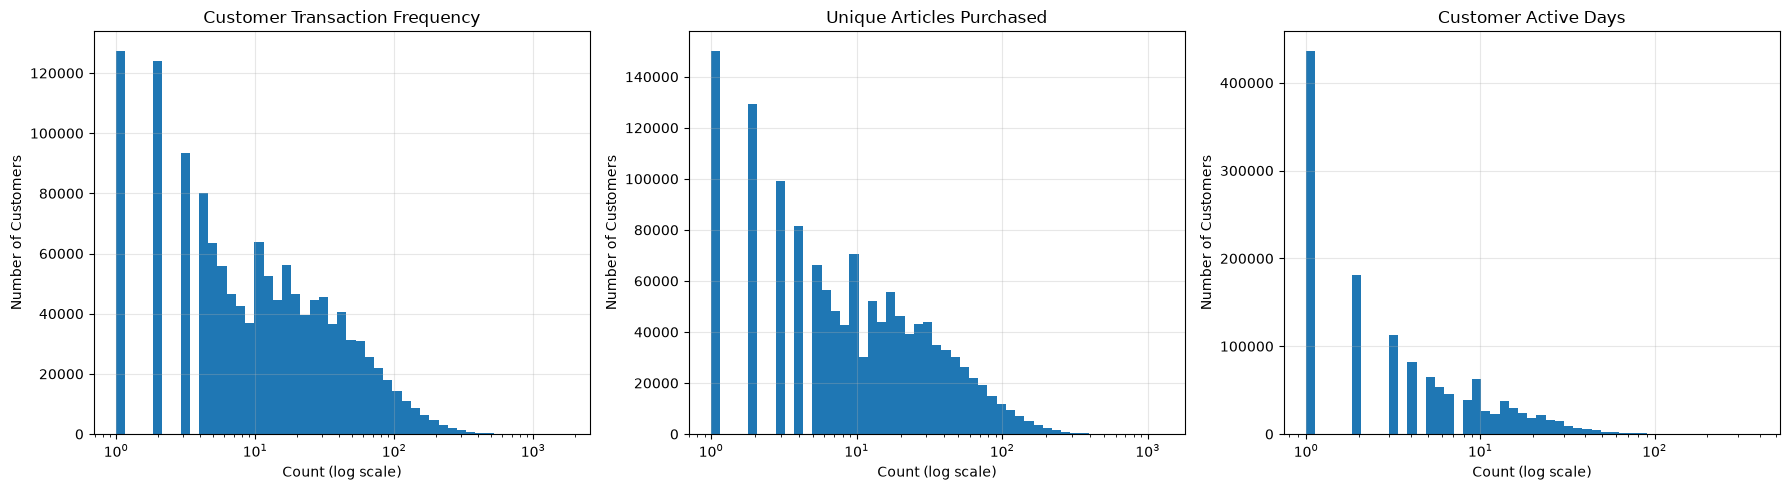

In [7]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features = [
    "total_transactions",
    "unique_articles",
    "active_days"
]

titles = [
    "Customer Transaction Frequency",
    "Unique Articles Purchased",
    "Customer Active Days"
]

for ax, feature, title in zip(axes, features, titles):

    values = customer_activity[feature]

    bins = np.geomspace(
        values.min(),
        values.max() + 1,
        50
    )

    ax.hist(values, bins=bins)
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("Count (log scale)")
    ax.set_ylabel("Number of Customers")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
import numpy as np

customer_activity["activity_segment"] = np.select(
    [
        customer_activity["total_transactions"] <= 3,
        customer_activity["total_transactions"] <= 9,
        customer_activity["total_transactions"] <= 26
    ],
    [
        "Low Activity",
        "Moderate Activity",
        "Active"
    ],
    default="Highly Active"
)

segment_summary = (
    customer_activity
    .groupby("activity_segment")
    .agg(
        customer_count=("customer_id", "count"),
        avg_transactions=("total_transactions", "mean"),
        avg_unique_articles=("unique_articles", "mean"),
        avg_active_days=("active_days", "mean")
    )
    .round(2)
)

segment_summary

,customer_count,avg_transactions,avg_unique_articles,avg_active_days
activity_segment,,,,
Active,327063,16.40,14.56,5.41
Highly Active,324557,67.05,56.64,17.12
Low Activity,344711,1.90,1.80,1.17
Moderate Activity,325438,6.06,5.48,2.21


## 2. Customer Demographic Analysis

This section examines customer age and purchasing behaviour to identify demographic patterns that may be useful for customer-aware recommendation models.

In [9]:
age_distribution = con.execute("""
    SELECT
        CASE
            WHEN age IS NULL THEN 'Unknown'
            WHEN age BETWEEN 16 AND 24 THEN '16–24'
            WHEN age BETWEEN 25 AND 34 THEN '25–34'
            WHEN age BETWEEN 35 AND 44 THEN '35–44'
            WHEN age BETWEEN 45 AND 54 THEN '45–54'
            WHEN age BETWEEN 55 AND 64 THEN '55–64'
            ELSE '65+'
        END AS age_group,
        COUNT(*) AS customer_count,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS percentage
    FROM customers
    GROUP BY age_group
    ORDER BY
        CASE age_group
            WHEN '16–24' THEN 1
            WHEN '25–34' THEN 2
            WHEN '35–44' THEN 3
            WHEN '45–54' THEN 4
            WHEN '55–64' THEN 5
            WHEN '65+' THEN 6
            ELSE 7
        END
""").df()

age_distribution

,age_group,customer_count,percentage
0,16–24,357169,26.03
1,25–34,393292,28.67
2,35–44,169041,12.32
3,45–54,253951,18.51
4,55–64,139064,10.14
5,65+,43602,3.18
6,Unknown,15861,1.16


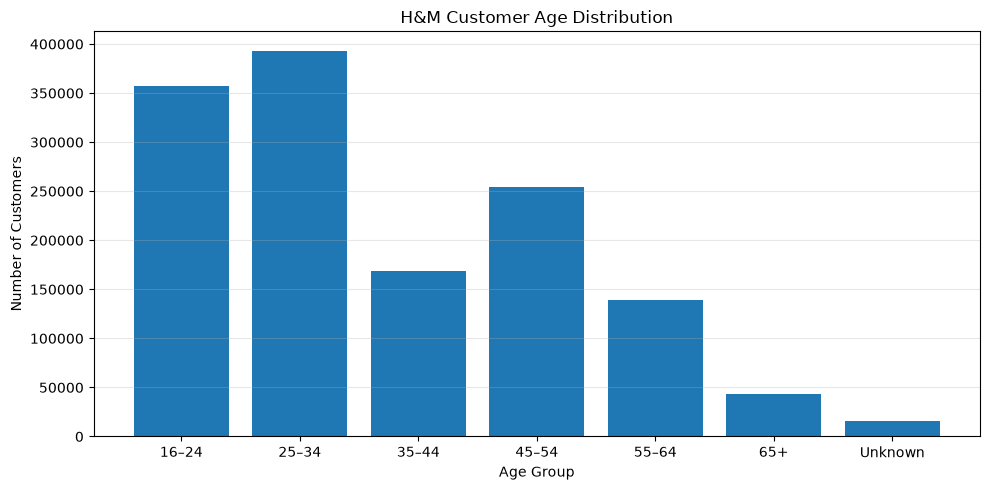

In [10]:
plt.figure(figsize=(10, 5))

plt.bar(
    age_distribution["age_group"],
    age_distribution["customer_count"]
)

plt.title("H&M Customer Age Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
age_purchase_behavior = con.execute("""
    SELECT
        CASE
            WHEN c.age IS NULL THEN 'Unknown'
            WHEN c.age BETWEEN 16 AND 24 THEN '16–24'
            WHEN c.age BETWEEN 25 AND 34 THEN '25–34'
            WHEN c.age BETWEEN 35 AND 44 THEN '35–44'
            WHEN c.age BETWEEN 45 AND 54 THEN '45–54'
            WHEN c.age BETWEEN 55 AND 64 THEN '55–64'
            ELSE '65+'
        END AS age_group,

        COUNT(DISTINCT t.customer_id) AS customer_count,
        ROUND(AVG(customer_transactions), 2) AS avg_transactions,
        ROUND(AVG(unique_articles), 2) AS avg_unique_articles,
        ROUND(AVG(total_spend), 4) AS avg_spend

    FROM (
        SELECT
            customer_id,
            COUNT(*) AS customer_transactions,
            COUNT(DISTINCT article_id) AS unique_articles,
            SUM(price) AS total_spend
        FROM train_transactions
        GROUP BY customer_id
    ) t

    INNER JOIN customers c
        ON t.customer_id = c.customer_id

    GROUP BY age_group
    ORDER BY
        CASE age_group
            WHEN '16–24' THEN 1
            WHEN '25–34' THEN 2
            WHEN '35–44' THEN 3
            WHEN '45–54' THEN 4
            WHEN '55–64' THEN 5
            WHEN '65+' THEN 6
            ELSE 7
        END
""").df()

age_purchase_behavior

,age_group,customer_count,avg_transactions,avg_unique_articles,avg_spend
0,16–24,338984,17.80,15.54,0.4577
1,25–34,381518,28.39,24.28,0.7936
2,35–44,163473,23.66,20.13,0.6462
3,45–54,246231,23.25,19.90,0.6606
4,55–64,134343,19.54,16.74,0.5839
5,65+,41822,12.84,11.06,0.3933
6,Unknown,15398,8.61,7.50,0.2332


### Age-Based Purchasing Behaviour – Key Findings

- Customers aged 25–34 demonstrate the highest purchasing activity, with an average of 28.39 transactions and 24.28 unique articles.
- Customers aged 25–34 also have the highest average normalized spending (0.7936).
- Purchasing activity generally decreases across older age groups.
- Age may provide useful demographic information for customer-aware recommendation models.
- These findings are descriptive and do not establish a causal relationship between age and purchasing behaviour.

In [13]:
customer_preference_analysis = con.execute("""
    WITH customer_metrics AS (
        SELECT
            customer_id,
            COUNT(*) AS total_transactions,
            COUNT(DISTINCT article_id) AS unique_articles,
            SUM(price) AS total_spend
        FROM transactions
        GROUP BY customer_id
    )
    SELECT
        c.club_member_status,
        c.fashion_news_frequency,
        COUNT(*) AS customer_count,
        ROUND(AVG(m.total_transactions), 2) AS avg_transactions,
        ROUND(AVG(m.unique_articles), 2) AS avg_unique_articles,
        ROUND(AVG(m.total_spend), 4) AS avg_spend
    FROM customer_metrics m
    JOIN customers c
        ON m.customer_id = c.customer_id
    GROUP BY
        c.club_member_status,
        c.fashion_news_frequency
    ORDER BY customer_count DESC
""").df()

customer_preference_analysis

,club_member_status,fashion_news_frequency,customer_count,avg_transactions,avg_unique_articles,avg_spend
0,ACTIVE,NONE,782731,22.20,19.08,0.6207
1,ACTIVE,Regularly,467759,28.98,24.91,0.7983
2,PRE-CREATE,NONE,84711,7.06,5.91,0.2127
3,ACTIVE,NaN,11916,9.64,8.50,0.2611
4,PRE-CREATE,Regularly,5759,8.26,6.95,0.2550
5,NaN,NONE,3698,12.08,10.08,0.3554
6,PRE-CREATE,NaN,2049,6.97,5.88,0.2309
7,NaN,NaN,2034,6.20,5.27,0.1885
8,ACTIVE,Monthly,776,12.89,11.73,0.3214
9,LEFT CLUB,NONE,458,18.48,15.69,0.5595


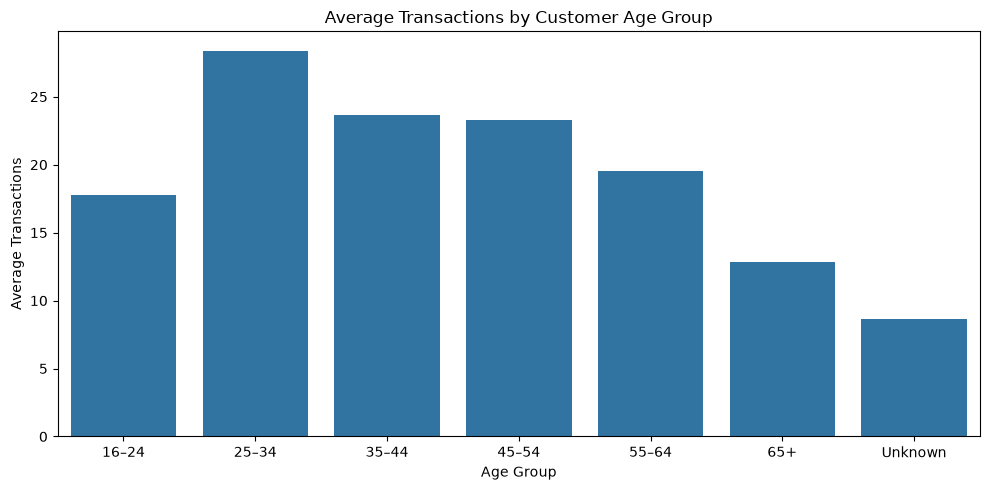

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_purchase_behavior,
    x="age_group",
    y="avg_transactions"
)

plt.title("Average Transactions by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:
customer_activity["activity_segment"] = pd.cut(
    customer_activity["total_transactions"],
    bins=[0, 5, 10, 20, 50, 100, float("inf")],
    labels=[
        "1–5",
        "6–10",
        "11–20",
        "21–50",
        "51–100",
        "100+"
    ]
)

activity_distribution = (
    customer_activity["activity_segment"]
    .value_counts()
    .sort_index()
    .reset_index()
)

activity_distribution.columns = ["Activity Segment", "Customer Count"]

activity_distribution["Percentage"] = (
    activity_distribution["Customer Count"]
    / activity_distribution["Customer Count"].sum()
    * 100
).round(2)

activity_distribution

,Activity Segment,Customer Count,Percentage
0,1–5,488421,36.95
1,6–10,215660,16.32
2,11–20,215444,16.30
3,21–50,244415,18.49
4,51–100,107788,8.15
5,100+,50041,3.79


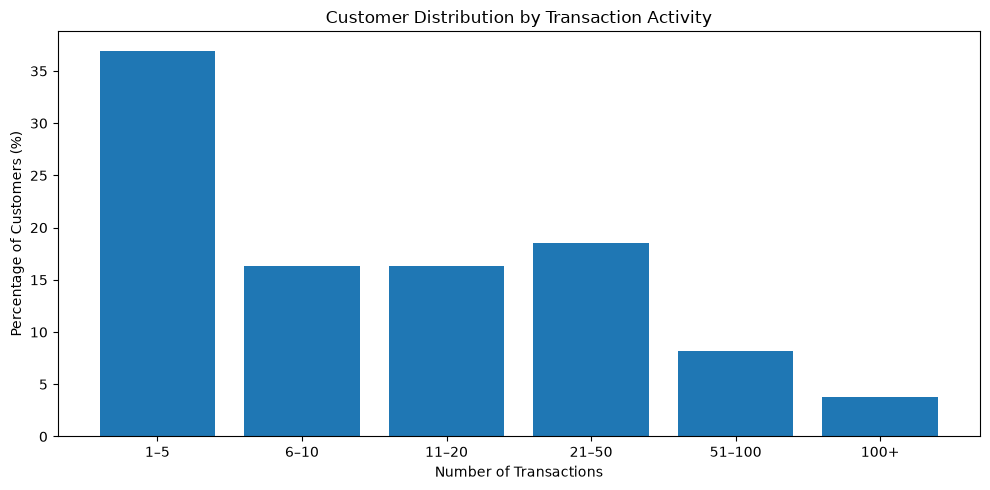

In [16]:
plt.figure(figsize=(10, 5))

plt.bar(
    activity_distribution["Activity Segment"].astype(str),
    activity_distribution["Percentage"]
)

plt.title("Customer Distribution by Transaction Activity")
plt.xlabel("Number of Transactions")
plt.ylabel("Percentage of Customers (%)")

plt.tight_layout()
plt.show()

### Customer Transaction Activity – Key Findings

The transaction activity analysis reveals an uneven distribution of customer engagement.

- Approximately 36.95% of customers recorded between 1 and 5 transactions.
- Around 34.79% recorded between 6 and 20 transactions.
- Approximately 22.24% recorded between 21 and 100 transactions.
- Only 3.79% recorded more than 100 transactions.

These findings indicate that the customer base contains different levels of purchasing activity. This is important for recommendation modelling because highly active customers provide more historical interaction data, whereas customers with limited purchase histories may present a cold-start or sparse-data challenge.

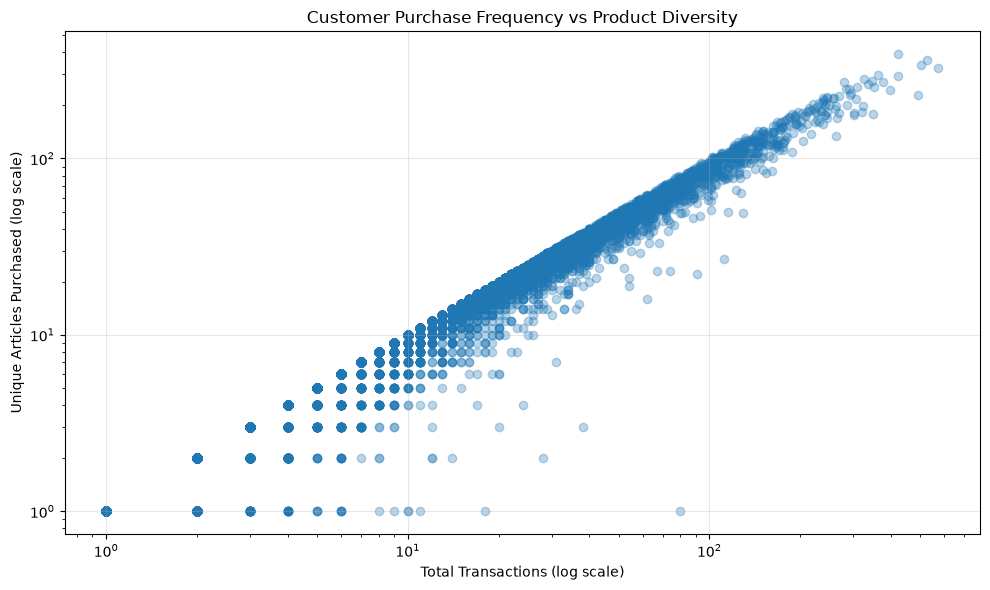

In [17]:
plt.figure(figsize=(10, 6))

sample = customer_activity.sample(
    n=min(10000, len(customer_activity)),
    random_state=42
)

plt.scatter(
    sample["total_transactions"],
    sample["unique_articles"],
    alpha=0.3
)

plt.xscale("log")
plt.yscale("log")

plt.title("Customer Purchase Frequency vs Product Diversity")
plt.xlabel("Total Transactions (log scale)")
plt.ylabel("Unique Articles Purchased (log scale)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Customer Purchase Frequency vs Product Diversity – Key Findings

The scatter plot reveals a strong positive relationship between total transaction frequency and the number of unique articles purchased.

- Customers with higher transaction frequencies generally purchase a wider variety of products.
- Customers with fewer transactions tend to have lower product diversity.
- Some highly active customers purchase a relatively smaller variety of products, indicating repeated purchases.

This relationship highlights differences in customer purchasing behaviour. It is relevant to recommendation systems because customers with extensive purchase histories provide more information for personalized recommendations, while customers with limited histories may require alternative recommendation strategies.

In [18]:
club_analysis = (
    customer_preference_analysis
    .groupby("club_member_status")
    .apply(
        lambda group: pd.Series({
            "customer_count": group["customer_count"].sum(),
            "avg_transactions": (
                (group["avg_transactions"] * group["customer_count"]).sum()
                / group["customer_count"].sum()
            ),
            "avg_unique_articles": (
                (group["avg_unique_articles"] * group["customer_count"]).sum()
                / group["customer_count"].sum()
            )
        }),
        include_groups=False
    )
    .round(2)
    .reset_index()
)

club_analysis

,club_member_status,customer_count,avg_transactions,avg_unique_articles
0,ACTIVE,1263183.0,24.59,21.13
1,LEFT CLUB,466.0,18.32,15.57
2,PRE-CREATE,92578.0,7.13,5.97


### Customer Purchasing Behaviour by Club Membership Status

The analysis indicates differences in purchasing activity across club membership categories.

- ACTIVE members recorded the highest average transaction frequency (24.59) and product diversity (21.13 unique articles).
- PRE-CREATE customers recorded lower averages of 7.13 transactions and 5.97 unique articles.
- LEFT CLUB customers recorded averages of 18.32 transactions and 15.57 unique articles. However, this group contains only 466 customers, so its results should be interpreted cautiously.

These findings suggest that membership status may be useful as a customer attribute in personalized recommendation models. However, the observed differences do not establish a causal relationship between membership status and purchasing behaviour.